# Childhood Cancer Incidence Across Age Groups
### Neuroblastoma and ganglioneuroblastoma

## Purpose and audience

This project is for students and other people interested in childhood
cancer who want to explore how reported incidence differs across age
groups and registry populations.

**Main question:** How do reported neuroblastoma and ganglioneuroblastoma
incidence rates differ across age groups, and how consistently does the
youngest age group have the highest rate across registry entries?

## Data source and observation unit

The data comes from Table 8.12 of the International Agency for Research
on Cancer’s International Incidence of Childhood Cancer, Volume III,
printed pages 514–515.

Each row represents a registry population or group of registries over
a specified reporting period. Rows can describe national populations,
selected regions, or population subgroups. They do not represent
individual patients or necessarily independent populations.

The table combines neuroblastoma and ganglioneuroblastoma into one
diagnostic category, IVa. The main variables used here are age-specific
incidence rates per million for ages 0–4, 5–9, 10–14, and 15–19.

## Scope

This is a descriptive analysis of historical registry data. It does
not estimate individual risk, explain causes, compare treatments,
or measure changes over time. Reporting periods and population
coverage differ, and some entries overlap.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("neuroblastoma_clean.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (121, 16)


,registry_period,cases_0_14,asr_0_14_all,asr_0_14_male,asr_0_14_female,cases_0_19,asr_0_19_all,asr_0_19_male,asr_0_19_female,rate_0_4,rate_5_9,rate_10_14,rate_15_19,registry,start_year,end_year
0,"ALGERIA, 5 registries (1996-2014)",112,7.2,8.1,6.3,117.0,5.7,6.5,4.9,14.8,3.3,1.5,0.7,"ALGERIA, 5 registries",1996,2014
1,BOTSWANA (1999-2007),7,1.4,0.8,2.0,7.0,1.1,0.6,1.6,3.6,0.0,0.0,0.0,BOTSWANA,1999,2007
2,"CAMEROON, Yaoundé (2004-2006)",1,0.4,0.9,0.0,1.0,0.3,0.7,0.0,1.1,0.0,0.0,0.0,"CAMEROON, Yaoundé",2004,2006
3,"EGYPT, Gharbiah (1999-2010)",133,10.1,11.2,9.0,135.0,7.9,8.7,7.1,20.0,6.7,0.7,0.4,"EGYPT, Gharbiah",1999,2010
4,"FRANCE, Réunion (1990-2011)",30,7.6,8.2,7.1,32.0,6.2,6.7,5.8,16.4,3.4,0.7,1.4,"FRANCE, Réunion",1990,2011


## Data quality checks

Before continuing the analysis, I will inspect the column types,
missing values, and duplicate rows. These checks will help me decide
whether any additional cleaning is needed.

Missing rates will remain missing. Replacing them with zero would
incorrectly treat an unavailable rate as a reported zero.

In [2]:
# Summarize data types and missing values
quality_summary = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(1)
})

display(quality_summary)

print("Exact duplicate rows:", df.duplicated().sum())
print(
    "Duplicate registry-period labels:",
    df["registry_period"].duplicated().sum()
)

,data_type,missing_count,missing_percent
registry_period,str,0,0.0
cases_0_14,int64,0,0.0
asr_0_14_all,float64,0,0.0
asr_0_14_male,float64,0,0.0
asr_0_14_female,float64,0,0.0
cases_0_19,float64,23,19.0
asr_0_19_all,float64,23,19.0
asr_0_19_male,float64,23,19.0
asr_0_19_female,float64,23,19.0
rate_0_4,float64,0,0.0


Exact duplicate rows: 0
Duplicate registry-period labels: 0


### Data-quality findings and decisions

There are no exact duplicate rows or repeated registry-period labels.
However, some entries cover overlapping populations, which is different
from having duplicate rows.

All entries have rates for ages 0–4, 5–9, and 10–14. The rate for
ages 15–19 and the summary measures for ages 0–19 are unavailable
in 23 entries (19.0%).

I will keep these values as missing rather than impute them or replace
them with zero. Comparisons requiring all four age groups will use the
98 complete entries. Comparisons using only the younger groups can
retain entries with those rates available.

The rate columns are numeric, and the registry labels are text.
The case-count column for ages 0–19 is stored as a float because it
contains missing values; this does not mean the counts are fractional.

In [3]:
numeric_columns = df.select_dtypes(include="number").columns

print("Negative values by numeric column:")
display((df[numeric_columns] < 0).sum())

print("Entries with start year after end year:",
      (df["start_year"] > df["end_year"]).sum())

both_counts = df.dropna(subset=["cases_0_14", "cases_0_19"])
print("Entries where cases aged 0–19 are fewer than cases aged 0–14:",
      (both_counts["cases_0_19"] < both_counts["cases_0_14"]).sum())

Negative values by numeric column:


cases_0_14         0
asr_0_14_all       0
asr_0_14_male      0
asr_0_14_female    0
cases_0_19         0
asr_0_19_all       0
asr_0_19_male      0
asr_0_19_female    0
rate_0_4           0
rate_5_9           0
rate_10_14         0
rate_15_19         0
start_year         0
end_year           0
dtype: int64

Entries with start year after end year: 0
Entries where cases aged 0–19 are fewer than cases aged 0–14: 0


### Numerical validity checks

No negative values were found in the numeric columns. All reporting
periods have a start year no later than the end year. Where both case
counts are available, the count for ages 0–19 is at least as large
as the count for ages 0–14.

These checks found no problems with those basic consistency rules.
They do not establish that every extracted value is correct.

### Reviewing the range of incidence rates

I will inspect the distribution of each age-specific rate and identify
the entries with the highest values. Unusual values need investigation,
but they should not be removed simply because they are high.

In [4]:
age_columns = ["rate_0_4", "rate_5_9", "rate_10_14", "rate_15_19"]

display(df[age_columns].describe().round(2))

for column in age_columns:
    print(f"\nHighest reported values: {column}")
    display(
        df.nlargest(3, column)[["registry_period", column]]
    )

,rate_0_4,rate_5_9,rate_10_14,rate_15_19
count,121.00,121.00,121.00,98.00
mean,19.69,3.04,0.90,0.67
std,10.19,1.62,0.88,1.37
min,1.10,0.00,0.00,0.00
25%,12.60,2.00,0.50,0.02
50%,19.40,2.90,0.80,0.40
75%,27.70,3.80,1.10,0.70
max,43.30,8.40,5.40,8.50



Highest reported values: rate_0_4


,registry_period,rate_0_4
87,"ITALY, 2 paediatric registries (1998-2011)",43.3
103,"SPAIN, Valencia, paediatric (1991-2010)",41.9
84,"HUNGARY, paediatric (1991-2014)",39.8



Highest reported values: rate_5_9


,registry_period,rate_5_9
91,MALTA (1994-2013),8.4
59,LEBANON (2008-2010),7.9
96,"RUSSIAN FEDERATION, Moscow region, paediatric ...",6.9



Highest reported values: rate_10_14


,registry_period,rate_10_14
58,"KUWAIT, Non-Kuwaitis (1994-2012)",5.4
56,KUWAIT (1994-2012),4.9
57,"KUWAIT, Kuwaitis (1994-2012)",4.6



Highest reported values: rate_15_19


,registry_period,rate_15_19
57,"KUWAIT, Kuwaitis (1994-2012)",8.5
56,KUWAIT (1994-2012),8.0
58,"KUWAIT, Non-Kuwaitis (1994-2012)",7.3


### Rate ranges and unusual values

The median reported rates across available entries are 19.4 for
ages 0–4, 2.9 for ages 5–9, 0.8 for ages 10–14, and 0.4 for
ages 15–19, all per million.

The highest rate for ages 0–4 is 43.3 in the entry covering two
Italian paediatric registries. The Kuwait entries have the highest
reported rates for ages 10–14 and 15–19. These values match
Table 8.12, so I will retain them rather than remove them simply
because they are unusual.

These are unweighted summaries of registry entries, not global
population rates. Some entries overlap, reporting periods differ,
and ages 15–19 have fewer available observations. Therefore,
these medians alone are not a comparison of identical populations
across all four age groups.

### Decisions about data preparation and methods

- **Missing values:** I will leave unavailable rates as missing.
  Imputation would introduce estimates that are not reported in
  the source. Each analysis will use entries with the rates it needs.

- **Duplicates and overlapping populations:** No exact duplicates
  were found. However, overall populations and their subgroups can
  overlap. I will retain their labels and avoid adding their case
  counts together or treating them as independent countries.

- **Unusual values:** I will retain the checked high values because
  they match the published table. A high value alone is not evidence
  of a data error.

- **Scaling and encoding:** The four age-specific rates already use
  the same units, so scaling is unnecessary for direct comparison.
  Registry names are labels and do not need numeric encoding.

- **Reshaping:** For the app, I will reshape the age-rate columns
  into a long format with one row per registry entry and age group.
  This will make filtering and plotting easier without changing
  the reported values.

- **Modeling and integration:** The current question is descriptive,
  so a predictive model is unnecessary. I will use the existing
  source rather than add another dataset without a clear purpose.

## Reshaping the data for plotting and interaction

I will convert the four age-rate columns into two columns:
age group and incidence rate. Each original registry entry will
have four rows, one for each age group.

Missing rates will stay missing. This changes the table’s layout,
not its reported values.

In [5]:
age_mapping = {
    "rate_0_4": "0–4",
    "rate_5_9": "5–9",
    "rate_10_14": "10–14",
    "rate_15_19": "15–19"
}

long_df = df.melt(
    id_vars=["registry_period", "registry", "start_year", "end_year"],
    value_vars=age_columns,
    var_name="age_group",
    value_name="incidence_rate"
)

long_df["age_group"] = long_df["age_group"].map(age_mapping)

# Preserve the intended age order
long_df["age_group"] = pd.Categorical(
    long_df["age_group"],
    categories=list(age_mapping.values()),
    ordered=True
)

# Check the reshaping against the original values
restored = long_df.pivot(
    index="registry_period",
    columns="age_group",
    values="incidence_rate"
)

original = df.set_index("registry_period")[age_columns].copy()
original.columns = list(age_mapping.values())

pd.testing.assert_frame_equal(
    restored.reindex(index=original.index, columns=original.columns),
    original,
    check_names=False,
    check_index_type=False,
    check_column_type=False
)

print("Original rows:", len(df))
print("Long-format rows:", len(long_df))
print("Missing rates:", long_df["incidence_rate"].isna().sum())
print("Check passed: all rates and missing values were preserved.")

long_df.head(8)

Original rows: 121
Long-format rows: 484
Missing rates: 23
Check passed: all rates and missing values were preserved.


,registry_period,registry,start_year,end_year,age_group,incidence_rate
0,"ALGERIA, 5 registries (1996-2014)","ALGERIA, 5 registries",1996,2014,0–4,14.8
1,BOTSWANA (1999-2007),BOTSWANA,1999,2007,0–4,3.6
2,"CAMEROON, Yaoundé (2004-2006)","CAMEROON, Yaoundé",2004,2006,0–4,1.1
3,"EGYPT, Gharbiah (1999-2010)","EGYPT, Gharbiah",1999,2010,0–4,20.0
4,"FRANCE, Réunion (1990-2011)","FRANCE, Réunion",1990,2011,0–4,16.4
5,"KENYA, 2 registries (2000-2012)","KENYA, 2 registries",2000,2012,0–4,3.0
6,"LIBYA, Benghazi (2003-2008)","LIBYA, Benghazi",2003,2008,0–4,15.7
7,"MALI, Bamako (2005-2014)","MALI, Bamako",2005,2014,0–4,4.7


## Incidence across age groups in the USA

I will start by comparing the reported incidence rates for ages 0–4,
5–9, 10–14, and 15–19 in the overall USA entry for 1998–2012.

I am selecting one registry entry so the first comparison uses the
same reporting period and geographic coverage for all four age groups.
The separate US subgroup entries are excluded from this chart.

**Question:** How does reported incidence differ across age groups
in the USA?

In [6]:
age_columns = [
    "rate_0_4",
    "rate_5_9",
    "rate_10_14",
    "rate_15_19"
]

usa = df.loc[df["registry"] == "USA"]

usa[["registry_period"] + age_columns]

,registry_period,rate_0_4,rate_5_9,rate_10_14,rate_15_19
36,USA (1998-2012),28.4,3.4,1.0,0.4


### Comparing age groups with a bar chart

A bar chart lets me compare the four age groups directly. I will keep
the groups in age order and start the vertical axis at zero so the
bar heights show the differences accurately.

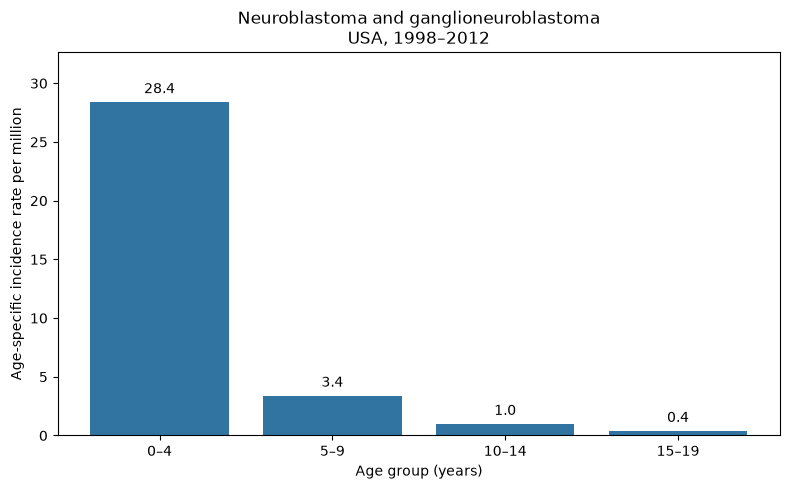

In [7]:
age_labels = ["0–4", "5–9", "10–14", "15–19"]
usa_rates = usa[age_columns].iloc[0].to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(age_labels, usa_rates, color="#3274A1")

ax.set_title("Neuroblastoma and ganglioneuroblastoma\nUSA, 1998–2012")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Age-specific incidence rate per million")
ax.set_ylim(0, max(usa_rates) * 1.15)
ax.bar_label(bars, fmt="%.1f", padding=4)

plt.tight_layout()
plt.show()

### Interpretation

The reported incidence rate is highest in children aged 0–4 at 28.4,
compared with 3.4 for ages 5–9, 1.0 for ages 10–14, and 0.4 for
ages 15–19. The rate for ages 0–4 is about 8.4 times the rate for
ages 5–9. This shows that reported incidence is concentrated in the
youngest age group in the USA entry for 1998–2012.

This comparison describes differences between age groups. It does
not explain why those differences exist or show changes over time.

## Checking the age pattern across registry entries

The USA chart shows the highest incidence rate in ages 0–4.
I will now check how often this pattern appears in entries with
reported rates for all four age groups.

Some entries cover overlapping populations and different reporting
periods, so this is a descriptive comparison of registry entries,
not an estimate of worldwide incidence.

In [8]:
# Keep entries with all four age-group rates available
complete = df.dropna(subset=age_columns).copy()

# Check whether ages 0–4 have a strictly higher rate
# than each of the three older age groups
youngest_highest = (
    complete["rate_0_4"]
    > complete[age_columns[1:]].max(axis=1)
)

print("Entries with all four rates:", len(complete))
print("Entries where ages 0–4 have the highest rate:",
      youngest_highest.sum())
print(f"Percentage: {youngest_highest.mean() * 100:.1f}%")

Entries with all four rates: 98
Entries where ages 0–4 have the highest rate: 95
Percentage: 96.9%


### Checking exceptions

Ages 0–4 have the highest reported rate in 95 of the 98 entries
with complete age-group data (96.9%). I will inspect the remaining
three entries to see how their age patterns differ.

In [9]:
exceptions = complete.loc[
    ~youngest_highest,
    ["registry_period"] + age_columns
]

exceptions

,registry_period,rate_0_4,rate_5_9,rate_10_14,rate_15_19
56,KUWAIT (1994-2012),7.2,2.7,4.9,8.0
57,"KUWAIT, Kuwaitis (1994-2012)",7.2,3.8,4.6,8.5
58,"KUWAIT, Non-Kuwaitis (1994-2012)",7.0,1.2,5.4,7.3


### Interpretation of the exceptions

The three exceptions are Kuwait overall, Kuwaitis, and non-Kuwaitis,
all covering 1994–2012. Each reports its highest incidence rate in
ages 15–19 rather than ages 0–4.

These entries describe an overall population and its subgroups,
so they are related observations. I checked these values against Table 8.12 of IARC’s International
Incidence of Childhood Cancer, Volume III (printed page 514),
and they match the published table. This confirms the reported
pattern, but does not explain why it occurs.

## Comparing the USA and Kuwait age patterns

I will use grouped bars to compare the age-specific incidence rates
in the overall USA and Kuwait entries. Kuwait is included because
its highest reported rate occurs in ages 15–19, unlike the USA.

The reporting periods differ: 1998–2012 for the USA and 1994–2012
for Kuwait. This comparison describes the reported patterns and
does not explain what causes the differences.

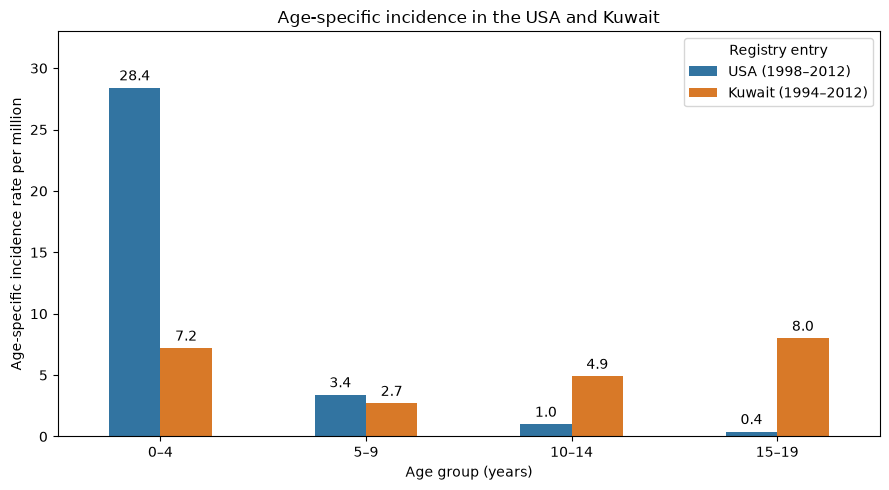

In [10]:
comparison = (
    df.loc[df["registry"].isin(["USA", "KUWAIT"])]
    .set_index("registry")
    .loc[["USA", "KUWAIT"], age_columns]
    .T
)

comparison.index = age_labels
comparison.columns = ["USA (1998–2012)", "Kuwait (1994–2012)"]

ax = comparison.plot.bar(
    figsize=(9, 5),
    color=["#3274A1", "#D87928"],
    rot=0
)

ax.set_title("Age-specific incidence in the USA and Kuwait")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Age-specific incidence rate per million")
ax.set_ylim(0, 33)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)

ax.legend(title="Registry entry")
plt.tight_layout()
plt.show()

### Interpretation

The USA and Kuwait show different age patterns. In the USA, the
reported incidence rate is highest at ages 0–4 and is lower in each
older age group. In Kuwait, the rate drops from 7.2 at ages 0–4 to
2.7 at ages 5–9, then rises to 8.0 at ages 15–19.

The USA has higher reported rates in the two younger age groups,
while Kuwait has higher rates in the two older groups. This shows
that the age pattern seen in the USA is not shared by every entry.

The reporting periods differ, and this chart alone cannot explain
the differences between the two populations.

## How age-specific rates vary across registry entries

I will use boxplots to compare the distribution of reported rates
across the 98 entries with all four age-group rates available.
Using the same entries makes the four distributions more comparable.

Each box shows the middle 50% of values, with a line marking the
median. Individual points show the registry entries.

These distributions describe overlapping registry entries with
different reporting periods, not independent countries or global rates.

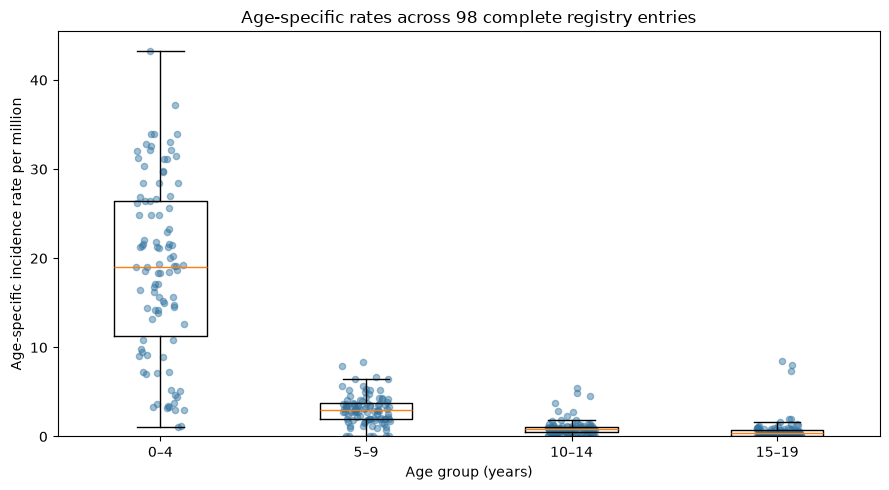

Median rates among the same 98 entries:


0–4      19.05
5–9       2.95
10–14     0.80
15–19     0.40
dtype: float64

In [11]:
import numpy as np

complete_rates = df.dropna(subset=age_columns)[age_columns]
age_labels = list(age_mapping.values())

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(
    [complete_rates[column].to_numpy() for column in age_columns],
    tick_labels=age_labels,
    showfliers=False
)

# Small horizontal offsets make overlapping points easier to see
rng = np.random.default_rng(42)

for position, column in enumerate(age_columns, start=1):
    values = complete_rates[column].to_numpy()
    offsets = rng.uniform(-0.12, 0.12, size=len(values))
    ax.scatter(
        position + offsets, values,
        alpha=0.45, s=20, color="#3274A1"
    )

ax.set_title("Age-specific rates across 98 complete registry entries")
ax.set_xlabel("Age group (years)")
ax.set_ylabel("Age-specific incidence rate per million")
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

print("Median rates among the same 98 entries:")
display(complete_rates.median().rename(index=age_mapping))

### Interpretation

Across the 98 entries with complete age-group data, the median
reported incidence rate is highest at ages 0–4: 19.05 per million.
The medians are 2.95 for ages 5–9, 0.80 for ages 10–14, and
0.40 for ages 15–19.

Rates for ages 0–4 also show a wider spread in absolute terms.
Most rates in the older groups are clustered near the lower end,
although a few entries have noticeably higher values.

This supports the finding that reported incidence is generally
highest in the youngest group, while showing variation across
registry populations. These are unweighted summaries of overlapping
entries with different reporting periods, not worldwide incidence
estimates. The 23 entries without rates for ages 15–19 are excluded.

## Checking the pattern when more entries are included

The four-age-group comparison excludes 23 entries because their
15–19 rates are unavailable. I will compare ages 0–4, 5–9, and
10–14 across all entries with those three rates available.

This checks whether the youngest-group pattern also appears in
the excluded entries. It cannot tell us their missing adolescent rates.

In [12]:
younger_columns = ["rate_0_4", "rate_5_9", "rate_10_14"]

younger_complete = df.dropna(subset=younger_columns).copy()

highest_under_15 = (
    younger_complete["rate_0_4"]
    > younger_complete[["rate_5_9", "rate_10_14"]].max(axis=1)
)

# Examine the entries excluded from the four-group comparison
missing_adolescent = younger_complete["rate_15_19"].isna()

print("Entries with all three younger-group rates:",
      len(younger_complete))
print("Entries where ages 0–4 are highest among these groups:",
      highest_under_15.sum())
print(f"Percentage: {highest_under_15.mean() * 100:.1f}%")

print("\nEntries without adolescent rates:",
      missing_adolescent.sum())
print("Of these, entries where ages 0–4 are highest:",
      highest_under_15[missing_adolescent].sum())

Entries with all three younger-group rates: 121
Entries where ages 0–4 are highest among these groups: 121
Percentage: 100.0%

Entries without adolescent rates: 23
Of these, entries where ages 0–4 are highest: 23


### Interpretation

Ages 0–4 have a higher reported incidence rate than both ages 5–9
and 10–14 in all 121 registry entries. This includes all 23 entries
excluded from the four-age-group comparison.

The youngest-group pattern therefore holds across every entry when
comparing the three groups under age 15. When ages 15–19 are included,
it holds in 95 of the 98 complete entries, with the three related
Kuwait entries as exceptions.

This check does not establish the pattern across all four age groups
for entries with missing adolescent rates. It also does not resolve
the overlap between registry populations.

## Main findings

Reported incidence is consistently highest in the youngest age group
when comparing children under 15: ages 0–4 have higher rates than
both ages 5–9 and 10–14 in all 121 registry entries.

Among the 98 entries with all four age-group rates available,
95 (96.9%) also have their highest rate at ages 0–4. The exceptions
are Kuwait overall and its two population subgroups, where the
highest reported rate occurs at ages 15–19.

The boxplots show that ages 0–4 have both the highest median rate
and the widest spread in absolute terms across the complete entries.
The USA–Kuwait comparison illustrates how individual age patterns
can differ from the broader pattern.

These findings describe the entries in this dataset. They are not
estimates of worldwide incidence or explanations of what causes
the differences.

## Limitations and next steps

### Limitations

- **Overlapping populations:** Some entries describe overall populations
  and their subgroups. They are not independent observations, so the
  percentages describe dataset entries rather than countries.

- **Different coverage and periods:** Entries cover different geographic
  areas and reporting periods. Comparisons do not isolate the effects
  of location or time.

- **Missing adolescent rates:** Rates for ages 15–19 are unavailable in
  23 entries. Findings across all four age groups apply only to the
  98 complete entries.

- **Unweighted summaries:** Each entry contributes equally to the
  medians, regardless of population size. These summaries are not
  estimates of global incidence.

- **Limited explanatory information:** The table contains aggregated
  counts and rates, not patient-level information. This analysis cannot
  explain the causes of age or population differences.

- **Uncertainty:** I have not calculated confidence intervals or tested
  statistical significance. Differences are described using the
  published, rounded rates.

### Next steps

I will build a Streamlit app that lets users select a registry entry,
compare age-specific rates across selected entries, and explore the
distribution of rates. The app will display reporting periods and
clearly distinguish unavailable rates from reported zeros.

A later extension could examine a carefully selected set of
non-overlapping populations and investigate registry-specific
background information before interpreting unusual patterns.


## Building the Streamlit app

This cell writes the initial app to app.py, including the project
purpose, data source, limitations, and a registry selector.

It writes only when the file is empty or missing, preserving any
existing app code.

In [13]:
import importlib.util
import sys

print("Python location:", sys.executable)

if importlib.util.find_spec("streamlit") is None:
    print("Streamlit is not installed in this environment.")
else:
    import streamlit
    print("Streamlit version:", streamlit.__version__)

Python location: /opt/anaconda3/bin/python
Streamlit version: 1.58.0


In [15]:
from pathlib import Path

app_path = Path.cwd() / "app.py"

if app_path.exists():
    print("app.py already exists; nothing was changed.")
else:
    app_path.touch()
    print("Created:", app_path)

app.py already exists; nothing was changed.


In [16]:
app_code = '''
from pathlib import Path

import pandas as pd
import streamlit as st

st.set_page_config(
    page_title="Childhood Cancer Incidence",
    layout="wide"
)

st.title("Childhood Cancer Incidence Across Age Groups")
st.subheader("Neuroblastoma and ganglioneuroblastoma")

st.write(
    "Explore how reported incidence rates differ across age groups "
    "and registry populations. This app is intended for students "
    "and others interested in understanding childhood cancer data."
)

data_path = Path(__file__).resolve().parent / "neuroblastoma_clean.csv"
df = pd.read_csv(data_path)

st.caption(
    "Source: IARC, International Incidence of Childhood Cancer, "
    "Volume III, Table 8.12. Age-specific rates are per million."
)

st.info(
    "These are historical registry data. Reporting periods differ, "
    "some populations overlap, and unavailable rates are not zeros."
)

st.subheader("Explore a registry entry")

selected_entry = st.selectbox(
    "Choose a registry population and reporting period",
    options=df["registry_period"].tolist(),
    index=df["registry_period"].tolist().index("USA (1998-2012)")
)

selected_row = df.loc[df["registry_period"] == selected_entry]
st.dataframe(selected_row, hide_index=True)
'''

app_path = Path.cwd() / "app.py"

if not app_path.exists() or app_path.stat().st_size == 0:
    app_path.write_text(app_code.lstrip(), encoding="utf-8")
    print("Saved the initial app:", app_path)
else:
    print("app.py already contains code; nothing was changed.")

Saved the initial app: /Users/mr.kohli/Documents/CMSE_830/CMSE830_Neuroblastoma/app.py


### Running the app locally

This cell launches Streamlit using the notebook’s Python environment.
It checks whether port 8501 is occupied before starting a server.
An occupied port does not necessarily mean this project is running.

In [17]:
import subprocess
import sys
import socket
from pathlib import Path

port = 8501

with socket.socket() as connection:
    port_in_use = connection.connect_ex(("127.0.0.1", port)) == 0

if port_in_use:
    print("Port 8501 is already in use. Check the app in your browser.")
else:
    log_path = Path.cwd() / "streamlit.log"

    with log_path.open("a") as log:
        app_process = subprocess.Popen(
            [
                sys.executable, "-m", "streamlit", "run",
                str(Path.cwd() / "app.py"),
                "--server.port", str(port),
                "--server.headless", "true"
            ],
            stdout=log,
            stderr=subprocess.STDOUT
        )

    print("Launch requested. Open the link below.")

print("http://localhost:8501")

Launch requested. Open the link below.
http://localhost:8501


### Exploring one registry entry

This cell adds an age-group bar chart linked to the registry selector.
Unavailable rates are labelled separately from reported zeros.
A marker prevents the same code block from being added twice.

In [18]:
chart_code = '''
# AGE_GROUP_CHART
import matplotlib.pyplot as plt

age_columns = ["rate_0_4", "rate_5_9", "rate_10_14", "rate_15_19"]
age_labels = ["0–4", "5–9", "10–14", "15–19"]

rates = selected_row[age_columns].iloc[0].to_numpy(dtype=float)

st.subheader("How does incidence differ across age groups?")
st.write(selected_entry)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(age_labels, rates, color="#3274A1")

ax.set_xlabel("Age group (years)")
ax.set_ylabel("Age-specific incidence rate per million")
ax.set_ylim(0, max(rates[~pd.isna(rates)]) * 1.2)

for bar, rate in zip(bars, rates):
    if pd.notna(rate):
        ax.annotate(
            f"{rate:.1f}",
            (bar.get_x() + bar.get_width() / 2, rate),
            ha="center", va="bottom",
            xytext=(0, 4), textcoords="offset points"
        )
    else:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            0.03,
            "Unavailable",
            transform=ax.get_xaxis_transform(),
            ha="center", fontsize=9
        )

fig.tight_layout()
st.pyplot(fig)
plt.close(fig)

st.caption(
    "Compare the bar heights within this registry entry. "
    "Unavailable rates are left blank and labelled; they are not zeros. "
    "This chart compares age groups, not changes over time."
)
'''

app_path = Path.cwd() / "app.py"
current_code = app_path.read_text(encoding="utf-8")

if "# AGE_GROUP_CHART" not in current_code:
    app_path.write_text(current_code + "\n" + chart_code, encoding="utf-8")
    print("Added the age-group chart.")
else:
    print("The chart code is already present; nothing was changed.")

Added the age-group chart.


### Comparing registry entries

This cell adds a selector for up to three registry entries, a grouped
bar chart, and a table of the selected rates. Reporting periods remain
visible so users can consider differences in coverage and time.

The code is added only if its marker is absent from app.py.

In [19]:
comparison_code = '''
# REGISTRY_COMPARISON
st.subheader("Compare registry age patterns")

comparison_entries = st.multiselect(
    "Choose up to three registry entries",
    options=df["registry_period"].tolist(),
    default=["USA (1998-2012)", "KUWAIT (1994-2012)"],
    max_selections=3
)

if comparison_entries:
    comparison_data = (
        df.set_index("registry_period")
        .loc[comparison_entries, age_columns]
        .T
    )
    comparison_data.index = age_labels

    fig, ax = plt.subplots(figsize=(10, 5))

    comparison_data.plot.bar(
        ax=ax,
        rot=0,
        color=["#3274A1", "#D87928", "#3A8067"]
    )

    for container, entry in zip(ax.containers, comparison_entries):
        entry_rates = comparison_data[entry].to_numpy(dtype=float)

        labels = [
            f"{rate:.1f}" if pd.notna(rate) else "N/A"
            for rate in entry_rates
        ]
        ax.bar_label(container, labels=labels, padding=3, fontsize=9)

    maximum = comparison_data.max().max()
    ax.set_ylim(0, maximum * 1.2)
    ax.set_xlabel("Age group (years)")
    ax.set_ylabel("Age-specific incidence rate per million")
    ax.legend(title="Registry and reporting period", fontsize=8)

    fig.tight_layout()
    st.pyplot(fig)
    plt.close(fig)

    st.dataframe(comparison_data, na_rep="Unavailable")

    st.caption(
        "N/A indicates an unavailable rate. Reporting periods and "
        "population coverage differ, and selected entries may overlap. "
        "Differences do not establish their causes."
    )
else:
    st.info("Select at least one registry entry to show the comparison.")
'''

# Use pandas styling to label missing values in the displayed table
comparison_code = comparison_code.replace(
    'st.dataframe(comparison_data, na_rep="Unavailable")',
    'st.dataframe(comparison_data.style.format("{:.1f}", na_rep="Unavailable"))'
)

app_path = Path.cwd() / "app.py"
current_code = app_path.read_text(encoding="utf-8")

if "# REGISTRY_COMPARISON" not in current_code:
    app_path.write_text(
        current_code + "\n" + comparison_code,
        encoding="utf-8"
    )
    print("Added the registry comparison.")
else:
    print("Comparison code already exists; nothing was changed.")

Added the registry comparison.


### Showing the broader age pattern

The next app section will show how age-specific rates vary across
the 98 registry entries with all four rates available. Boxplots
and individual points will provide context for the selected examples.

The section will explain that these are overlapping registry entries,
not independent countries or a population-weighted global sample.

In [20]:
distribution_code = '''
# OVERALL_DISTRIBUTION
import numpy as np

st.subheader("Is the youngest-group pattern consistent?")

complete_rates = df.dropna(subset=age_columns)[age_columns]

youngest_highest = (
    complete_rates["rate_0_4"]
    > complete_rates[age_columns[1:]].max(axis=1)
)

st.write(
    f"Ages 0–4 have the highest reported rate in "
    f"{int(youngest_highest.sum())} of {len(complete_rates)} "
    f"complete registry entries "
    f"({youngest_highest.mean() * 100:.1f}%)."
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(
    [complete_rates[column].to_numpy() for column in age_columns],
    tick_labels=age_labels,
    showfliers=False
)

rng = np.random.default_rng(42)

for position, column in enumerate(age_columns, start=1):
    values = complete_rates[column].to_numpy()
    offsets = rng.uniform(-0.12, 0.12, len(values))

    ax.scatter(
        position + offsets,
        values,
        alpha=0.45,
        s=20,
        color="#3274A1"
    )

ax.set_xlabel("Age group (years)")
ax.set_ylabel("Age-specific incidence rate per million")
ax.set_ylim(bottom=0)

fig.tight_layout()
st.pyplot(fig)
plt.close(fig)

st.caption(
    "Each point represents one registry entry. Boxes show the middle "
    "50% of values; the line inside each box marks the median. "
    "Horizontal offsets separate points and have no analytical meaning. "
    "All observations are shown, including those beyond the whiskers."
)

median_table = pd.DataFrame({
    "Age group": age_labels,
    "Median rate per million": complete_rates.median().to_numpy()
})

st.dataframe(
    median_table.style.format({"Median rate per million": "{:.2f}"}),
    hide_index=True
)

st.write(
    "The youngest age group has the highest median and the widest "
    "spread in absolute rates. The three exceptions to its having "
    "the highest rate are Kuwait overall and its two population "
    "subgroups, where ages 15–19 have the highest reported rate."
)

st.caption(
    "These are unweighted summaries of overlapping registry entries "
    "with different reporting periods, not worldwide incidence estimates. "
    "The 23 entries without adolescent rates are excluded here."
)
'''

app_path = Path.cwd() / "app.py"
current_code = app_path.read_text(encoding="utf-8")

if "# OVERALL_DISTRIBUTION" not in current_code:
    app_path.write_text(
        current_code + "\n" + distribution_code,
        encoding="utf-8"
    )
    print("Added the overall distribution section.")
else:
    print("This section already exists; nothing was changed.")

Added the overall distribution section.


### Checking entries with missing adolescent rates

This section explains that ages 0–4 have the highest rate among
the three younger groups in all 121 entries, including the 23
without adolescent rates. It does not estimate the missing rates.

In [21]:
missing_check_code = '''
# MISSING_DATA_CHECK
st.subheader("What about entries without adolescent rates?")

younger_columns = ["rate_0_4", "rate_5_9", "rate_10_14"]
younger_complete = df.dropna(subset=younger_columns)

highest_under_15 = (
    younger_complete["rate_0_4"]
    > younger_complete[younger_columns[1:]].max(axis=1)
)

missing_adolescent = younger_complete["rate_15_19"].isna()

st.write(
    f"Ages 0–4 have higher reported rates than both ages 5–9 "
    f"and 10–14 in {int(highest_under_15.sum())} of "
    f"{len(younger_complete)} entries. This includes all "
    f"{int(missing_adolescent.sum())} entries without adolescent rates."
)

st.caption(
    "This supports the pattern among children under 15. "
    "It cannot establish which of all four age groups has the "
    "highest rate where adolescent data are unavailable."
)
'''

app_path = Path.cwd() / "app.py"
current_code = app_path.read_text(encoding="utf-8")

if "# MISSING_DATA_CHECK" not in current_code:
    app_path.write_text(
        current_code + "\n" + missing_check_code,
        encoding="utf-8"
    )
    print("Added the missing-data explanation.")
else:
    print("This section already exists; nothing was changed.")

Added the missing-data explanation.


### Explaining data quality in the app

This section summarizes missing values, duplicate checks, and
preparation decisions. An expandable panel provides detail without
interrupting the main data story.

In [22]:
quality_code = '''
# DATA_QUALITY_PANEL
with st.expander("Data quality and preparation"):
    st.write(
        "Each row represents a registry population over a reporting "
        "period, not an individual patient. The dataset combines "
        "neuroblastoma and ganglioneuroblastoma into category IVa."
    )

    quality_table = pd.DataFrame({
        "Age group": age_labels,
        "Available rates": df[age_columns].notna().sum().to_numpy(),
        "Unavailable rates": df[age_columns].isna().sum().to_numpy()
    })

    st.dataframe(quality_table, hide_index=True)

    st.write(
        f"Exact duplicate rows: {int(df.duplicated().sum())}. "
        f"Repeated registry-period labels: "
        f"{int(df['registry_period'].duplicated().sum())}."
    )

    st.markdown(
        """
- Missing rates remain unavailable; they are not replaced or imputed.
- Reported zeros are retained.
- Unusual values are not removed simply because they are high.
- Rates already share the same units, so scaling is unnecessary.
- Overlapping populations remain labelled and are not pooled.
- Selected values were checked against the published table;
  a full cell-by-cell verification has not been completed.
        """
    )
'''

app_path = Path.cwd() / "app.py"
current_code = app_path.read_text(encoding="utf-8")

if "# DATA_QUALITY_PANEL" not in current_code:
    app_path.write_text(
        current_code + "\n" + quality_code,
        encoding="utf-8"
    )
    print("Added the data-quality panel.")
else:
    print("This section already exists; nothing was changed.")

Added the data-quality panel.


### Explaining limitations and citing the source

The app ends with limitations and a source reference so users can
understand the boundaries of the findings and locate the original data.

In [23]:
limitations_code = '''
# LIMITATIONS_AND_SOURCE
st.subheader("Limitations")

st.markdown(
    """
- **Overlapping populations:** Entries can include overall populations
  and their subgroups. They are not independent countries.
- **Different coverage and periods:** Geographic coverage and reporting
  periods vary. These data do not establish current rates or time trends.
- **Missing adolescent rates:** Four-group comparisons exclude entries
  without rates for ages 15–19.
- **Unweighted summaries:** Registry entries contribute equally to the
  medians. These are not population-weighted global estimates.
- **Descriptive findings:** The analysis does not explain causes,
  estimate individual risk, or establish statistical significance.
    """
)

st.subheader("Data source")

st.markdown(
    """
International Agency for Research on Cancer,
*International Incidence of Childhood Cancer, Volume III*,
Table 8.12: Neuroblastoma and ganglioneuroblastoma (IVa),
printed pages 514–515.

[Visit the official IICC website](https://iicc.iarc.fr/)
    """
)

st.caption(
    "The app uses a cleaned transcription of the published table. "
    "Selected values were checked against the source; full "
    "cell-by-cell verification has not been completed."
)
'''

app_path = Path.cwd() / "app.py"
current_code = app_path.read_text(encoding="utf-8")

if "# LIMITATIONS_AND_SOURCE" not in current_code:
    app_path.write_text(
        current_code + "\n" + limitations_code,
        encoding="utf-8"
    )
    print("Added limitations and source.")
else:
    print("This section already exists; nothing was changed.")

Added limitations and source.


In [24]:
from pathlib import Path

project_folder = Path.cwd()

for filename in ["app.py", "neuroblastoma_clean.csv"]:
    path = project_folder / filename
    print(f"{filename}: {'Found' if path.is_file() else 'Missing'}")
    print(path)

app.py: Found
/Users/mr.kohli/Documents/CMSE_830/CMSE830_Neuroblastoma/app.py
neuroblastoma_clean.csv: Found
/Users/mr.kohli/Documents/CMSE_830/CMSE830_Neuroblastoma/neuroblastoma_clean.csv


### Simplifying the selected registry table

I will show age groups and incidence rates with readable labels,
instead of displaying all 16 dataset columns. Unavailable rates
will be labelled explicitly.

In [25]:
from pathlib import Path

app_path = Path.cwd() / "app.py"
current_code = app_path.read_text(encoding="utf-8")

old_code = "st.dataframe(selected_row, hide_index=True)"

new_code = '''# READABLE_REGISTRY_TABLE
registry_table = pd.DataFrame({
    "Age group (years)": ["0–4", "5–9", "10–14", "15–19"],
    "Incidence rate per million": selected_row[
        ["rate_0_4", "rate_5_9", "rate_10_14", "rate_15_19"]
    ].iloc[0].to_numpy(dtype=float)
})

st.dataframe(
    registry_table.style.format(
        {"Incidence rate per million": "{:.1f}"},
        na_rep="Unavailable"
    ),
    hide_index=True
)'''

if "# READABLE_REGISTRY_TABLE" in current_code:
    print("The table is already updated; nothing was changed.")
elif current_code.count(old_code) == 1:
    updated_code = current_code.replace(old_code, new_code, 1)
    compile(updated_code, str(app_path), "exec")
    app_path.write_text(updated_code, encoding="utf-8")
    print("Updated the registry table.")
else:
    print("Expected table code was not found exactly once; no changes made.")

Updated the registry table.


### Recording dependencies

This cell records the installed versions of the four packages used
by the app. The requirements file lets another user install those
versions. Rerunning the cell creates no additional copies.

In [26]:
from importlib.metadata import version
from pathlib import Path

packages = ["streamlit", "pandas", "numpy", "matplotlib"]

requirements_text = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
) + "\n"

requirements_path = Path.cwd() / "requirements.txt"

if requirements_path.exists():
    if requirements_path.read_text(encoding="utf-8") == requirements_text:
        print("requirements.txt is already up to date.")
    else:
        print("An existing requirements.txt has different contents.")
        print("Nothing was changed. Share its contents before replacing it.")
else:
    requirements_path.write_text(requirements_text, encoding="utf-8")
    print("Created requirements.txt.")

print("\nDetected package versions:")
print(requirements_text)

Created requirements.txt.

Detected package versions:
streamlit==1.58.0
pandas==3.0.3
numpy==2.4.6
matplotlib==3.11.0



### Documenting the project

This cell creates README.md with the project overview, data source,
setup instructions, main findings, and limitations. It preserves
an existing README when rerun.

In [28]:
from pathlib import Path

readme_text = """# Childhood Cancer Incidence Across Age Groups

CMSE 830 midterm project by Manas Kohli.

## Purpose and audience

This app helps students and others interested in childhood cancer
explore reported neuroblastoma and ganglioneuroblastoma incidence.

Main question: How do rates differ across age groups, and how
consistently does the youngest group have the highest rate?

## Data source

International Agency for Research on Cancer.
International Incidence of Childhood Cancer, Volume III.
Table 8.12, printed pages 514–515.

Official website: https://iicc.iarc.fr/

neuroblastoma_clean.csv contains 121 registry entries and 16 columns.
Each entry represents a registry population over a reporting period,
not an individual patient. Rates are age-specific rates per million.

Selected values were checked against the source table.
Full cell-by-cell verification has not been completed.

## Project files

Keep these files together:

- app.py
- neuroblastoma_clean.csv
- neuroblastoma_analysis.ipynb
- requirements.txt
- README.md

## Setup and run on macOS

Development environment: Python 3.14.

Open Terminal in the project folder and run:

```bash
python -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python -m streamlit run app.py
```

If your Python command is python3, use python3 for the first command.

Open the local URL printed by Streamlit.
Stop the server with Control+C.

To open the analysis notebook:

```bash
python -m pip install jupyterlab
python -m jupyter lab
```

Open neuroblastoma_analysis.ipynb from the project folder.
The CSV must be in the notebook's working directory.

The later notebook setup cells write app files and can launch a server.
They are not required to run the existing app.py.

## App features

- Explore rates for one registry entry.
- Compare up to three registry entries.
- View distributions across 98 complete entries.
- Review missing data, preparation decisions, and limitations.

Unavailable rates are distinguished from reported zeros.

## Main findings

- Ages 0–4 have higher rates than ages 5–9 and 10–14 in all 121 entries.
- Ages 0–4 have the highest rate across all four groups in 95 of
  the 98 complete entries (96.9%).
- The exceptions are Kuwait overall and its two population subgroups.
- Median rates across the same 98 entries are 19.05, 2.95, 0.80,
  and 0.40 per million across successive age groups.

## Limitations

Registry populations can overlap and reporting periods differ.
Entries are not independent countries. Adolescent rates are missing
in 23 entries. Summaries are unweighted, not global incidence estimates.
The analysis does not establish causes, statistical significance,
current rates, or individual risk.

## AI-use disclosure

See the Sources and AI-use disclosure section of the analysis notebook
for the tool/model, purposes, verification, and my contribution.
"""

readme_path = Path.cwd() / "README.md"

if readme_path.exists():
    print("README.md already exists; nothing was changed.")
else:
    readme_path.write_text(readme_text, encoding="utf-8")
    print("Created:", readme_path)

Created: /Users/mr.kohli/Documents/CMSE_830/CMSE830_Neuroblastoma/README.md


### Checking project files

This check confirms that the app, dataset, notebook, dependencies,
and README are present before preparing the GitHub repository.

In [29]:
from pathlib import Path

project_folder = Path.cwd()

required_files = [
    "app.py",
    "neuroblastoma_clean.csv",
    "neuroblastoma_analysis.ipynb",
    "requirements.txt",
    "README.md"
]

for filename in required_files:
    path = project_folder / filename
    status = "Found" if path.is_file() else "MISSING"
    print(f"{status}: {filename}")

print("\nNotebook files in this folder:")
for path in project_folder.glob("*.ipynb"):
    print(path.name)

Found: app.py
Found: neuroblastoma_clean.csv
Found: neuroblastoma_analysis.ipynb
Found: requirements.txt
Found: README.md

Notebook files in this folder:
neuroblastoma_analysis.ipynb


### Recording tested server dependencies

The clean-environment installation produced a server error when
serving charts. Matching Starlette, Uvicorn, and AnyIO to the working
environment restored the graphs. I will record those tested versions.

In [30]:
from pathlib import Path

requirements_path = Path.cwd() / "requirements.txt"

tested_requirements = """streamlit==1.58.0
pandas==3.0.3
numpy==2.4.6
matplotlib==3.11.0
starlette==1.3.1
uvicorn==0.40.0
anyio==4.12.1
"""

if requirements_path.read_text(encoding="utf-8") != tested_requirements:
    requirements_path.write_text(tested_requirements, encoding="utf-8")
    print("Updated requirements.txt with the tested versions.")
else:
    print("requirements.txt already matches the tested versions.")

print(requirements_path.read_text(encoding="utf-8"))

Updated requirements.txt with the tested versions.
streamlit==1.58.0
pandas==3.0.3
numpy==2.4.6
matplotlib==3.11.0
starlette==1.3.1
uvicorn==0.40.0
anyio==4.12.1



## Sources and AI-use disclosure

### Data source

International Agency for Research on Cancer.
International Incidence of Childhood Cancer, Volume III.
Table 8.12: Neuroblastoma and ganglioneuroblastoma (IVa),
numbers of cases and incidence rates by age and sex.
Printed pages 514–515.

Official project website: https://iicc.iarc.fr/

The analysis uses neuroblastoma_clean.csv, a cleaned transcription
of this table. Selected values, including the USA and Kuwait entries
and the highest rate for ages 0–4, were checked against the source.
A full cell-by-cell verification has not been completed.

### AI assistance

I used OpenAI ChatGPT to help write and explain Python code, troubleshoot errors and data-quality check including help checking missing values and duplicates, reshaping the data and explaining the plotting code.

I ran the code and reviewed its outputs. The reshaping check confirmed that the original rates and missing values were preserved. ChatGPT also compared selected values with the published source table.